# Project 2 – Concrete Compressive Strength
Predict concrete strength (MPa) from mixture composition and curing age.

1. Data exploration, preparation and mean baseline
2. Linear vs non-linear models, residual analysis
3. Does a predictive association imply a causal effect?

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, os
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, KFold, cross_val_predict
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.preprocessing import StandardScaler, FunctionTransformer, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
os.makedirs('figures', exist_ok=True)
plt.rcParams['figure.dpi'] = 100

## 1. Data exploration

In [2]:
df = pd.read_csv('data/Concrete_Data.csv')
df.columns = ['cement','slag','flyash','water','sp','coarse','fine','age','strength']
print(df.shape); print('missing values:', df.isna().sum().sum(), '| duplicate rows:', df.duplicated().sum())
df.describe().T.round(2)

(1030, 9)
missing values: 0 | duplicate rows: 25


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
flyash,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
water,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
sp,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
coarse,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
fine,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


In [3]:
print('Share of zeros:'); print((df[['slag','flyash','sp']]==0).mean().round(2))
print('\nSkewness:'); print(df.skew().round(2))
print('\nAge counts:'); print(df.age.value_counts().sort_index().to_string())
print('\nCorrelation with strength:'); print(df.corr()['strength'].round(2).drop('strength'))

Share of zeros:
slag      0.45
flyash    0.55
sp        0.37
dtype: float64

Skewness:
cement      0.51
slag        0.80
flyash      0.54
water       0.07
sp          0.91
coarse     -0.04
fine       -0.25
age         3.27
strength    0.42
dtype: float64

Age counts:
age
1        2
3      134
7      126
14      62
28     425
56      91
90      54
91      22
100     52
120      3
180     26
270     13
360      6
365     14

Correlation with strength:
cement    0.50
slag      0.13
flyash   -0.11
water    -0.29
sp        0.37
coarse   -0.16
fine     -0.17
age       0.33
Name: strength, dtype: float64


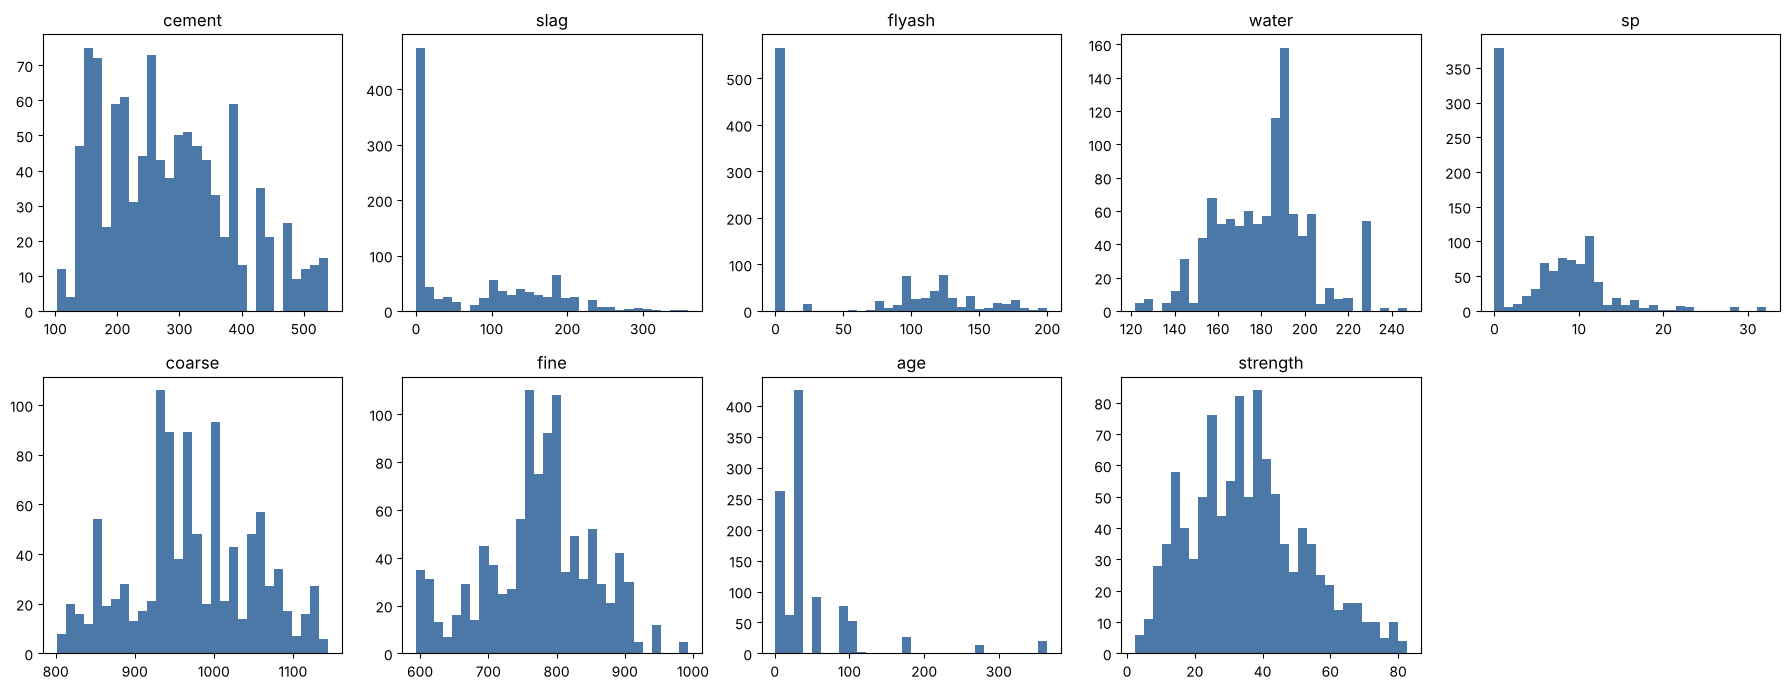

In [4]:
fig, ax = plt.subplots(2, 5, figsize=(18, 7))
for a, c in zip(ax.ravel(), df.columns): a.hist(df[c], bins=30, color='#4c78a8'); a.set_title(c)
ax.ravel()[-1].axis('off'); plt.tight_layout(); plt.savefig('figures/f1_dist.png'); plt.show()

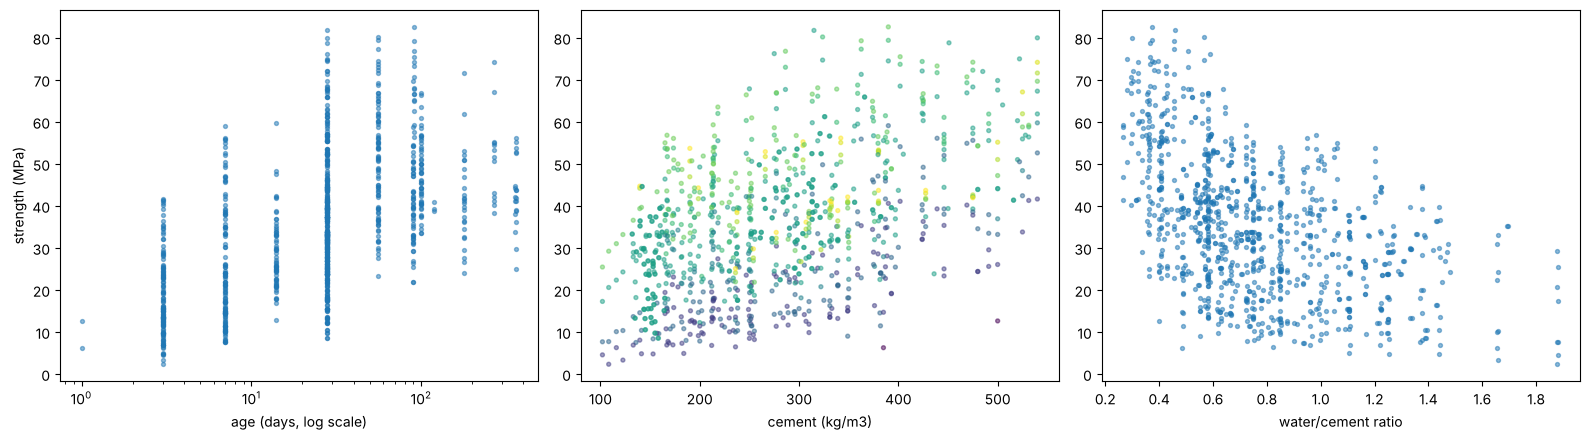

In [5]:
d = df.drop_duplicates().reset_index(drop=True)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(d.age, d.strength, s=8, alpha=.5); ax[0].set_xscale('log'); ax[0].set_xlabel('age (days, log scale)'); ax[0].set_ylabel('strength (MPa)')
ax[1].scatter(d.cement, d.strength, s=8, alpha=.5, c=np.log(d.age), cmap='viridis'); ax[1].set_xlabel('cement (kg/m3)')
ax[2].scatter(d.water/d.cement, d.strength, s=8, alpha=.5); ax[2].set_xlabel('water/cement ratio')
plt.tight_layout(); plt.savefig('figures/f2_rel.png'); plt.show()

## Data preparation (with justification)
- **Drop exact duplicates** (25 rows): they can fall in both train and test sets and inflate scores.
- **Keep zeros** in slag / fly ash / superplasticizer: they mean the ingredient is absent, not missing.
- **log(age)**: strength rises quickly then flattens; age is strongly right-skewed.
- **Water/cement ratio**: the classic physical driver of strength; a linear model can't form a ratio itself.
- **Standardise** for scale-sensitive models (ridge, SVR, MLP).
- **No outlier removal**: extreme strengths are genuine high-performance mixes.
- **Evaluation**: 80/20 split (seed 42) + 5-fold CV on the training part; the test set is never used for tuning.

In [6]:
y = d.strength.values; X = d.drop(columns='strength')
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(d), 'rows after de-duplication;', len(Xtr), 'train /', len(Xte), 'test')

def logage(X):
    X = X.copy(); X['age'] = np.log(X['age']); return X
def feat(X):
    X = X.copy(); X['age'] = np.log(X['age']); X['wc'] = X['water']/X['cement']; return X
LA, FE = FunctionTransformer(logage), FunctionTransformer(feat)

1005 rows after de-duplication; 804 train / 201 test


### Mean baseline and all models

In [7]:
models = {
 'Mean baseline': DummyRegressor(),
 'Linear (raw)': LinearRegression(),
 'Linear (log-age)': make_pipeline(LA, LinearRegression()),
 'Ridge (log-age + w/c)': make_pipeline(FE, StandardScaler(), RidgeCV(alphas=np.logspace(-3,3,30))),
 'Poly-2 Ridge': make_pipeline(FE, StandardScaler(), PolynomialFeatures(2), StandardScaler(), RidgeCV(alphas=np.logspace(-1,4,30))),
 'SVR (RBF)': make_pipeline(LA, StandardScaler(), SVR(C=50, epsilon=1, gamma=0.1)),
 'Neural net (MLP)': make_pipeline(LA, StandardScaler(), MLPRegressor(hidden_layer_sizes=(64,64), alpha=1e-2, max_iter=3000, random_state=0)),
 'Random forest': RandomForestRegressor(500, random_state=0, n_jobs=-1),
 'Gradient boosting': GradientBoostingRegressor(n_estimators=600, learning_rate=0.03, max_depth=4, subsample=0.7, random_state=0),
}
rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))
kf = KFold(5, shuffle=True, random_state=1); rows = []
for n, m in models.items():
    cv = cross_val_predict(m, Xtr, ytr, cv=kf)
    m.fit(Xtr, ytr); p = m.predict(Xte)
    rows.append([n, rmse(ytr, cv), r2_score(ytr, cv), rmse(yte, p), mean_absolute_error(yte, p), r2_score(yte, p)])
results = pd.DataFrame(rows, columns=['model','CV RMSE','CV R2','test RMSE','test MAE','test R2']).round(3)
results

,model,CV RMSE,CV R2,test RMSE,test MAE,test R2
0,Mean baseline,16.033,-0.002,17.297,13.972,-0.003
1,Linear (raw),10.197,0.594,11.192,8.896,0.580
2,Linear (log-age),7.056,0.806,7.653,5.839,0.804
3,Ridge (log-age + w/c),7.022,0.808,7.593,5.784,0.807
4,Poly-2 Ridge,5.679,0.874,6.200,4.484,0.871
5,SVR (RBF),4.895,0.907,5.150,3.232,0.911
6,Neural net (MLP),4.615,0.917,5.499,3.778,0.899
7,Random forest,5.460,0.884,5.178,3.507,0.910
8,Gradient boosting,4.490,0.921,4.334,2.805,0.937


## 2. Residual analysis
Out-of-fold (5-fold) predictions on all data for the best linear model and the best non-linear model.

OOF RMSE  linear: 7.13 | boosting: 4.37
Residual kurtosis  linear: 0.65 | boosting: 8.15


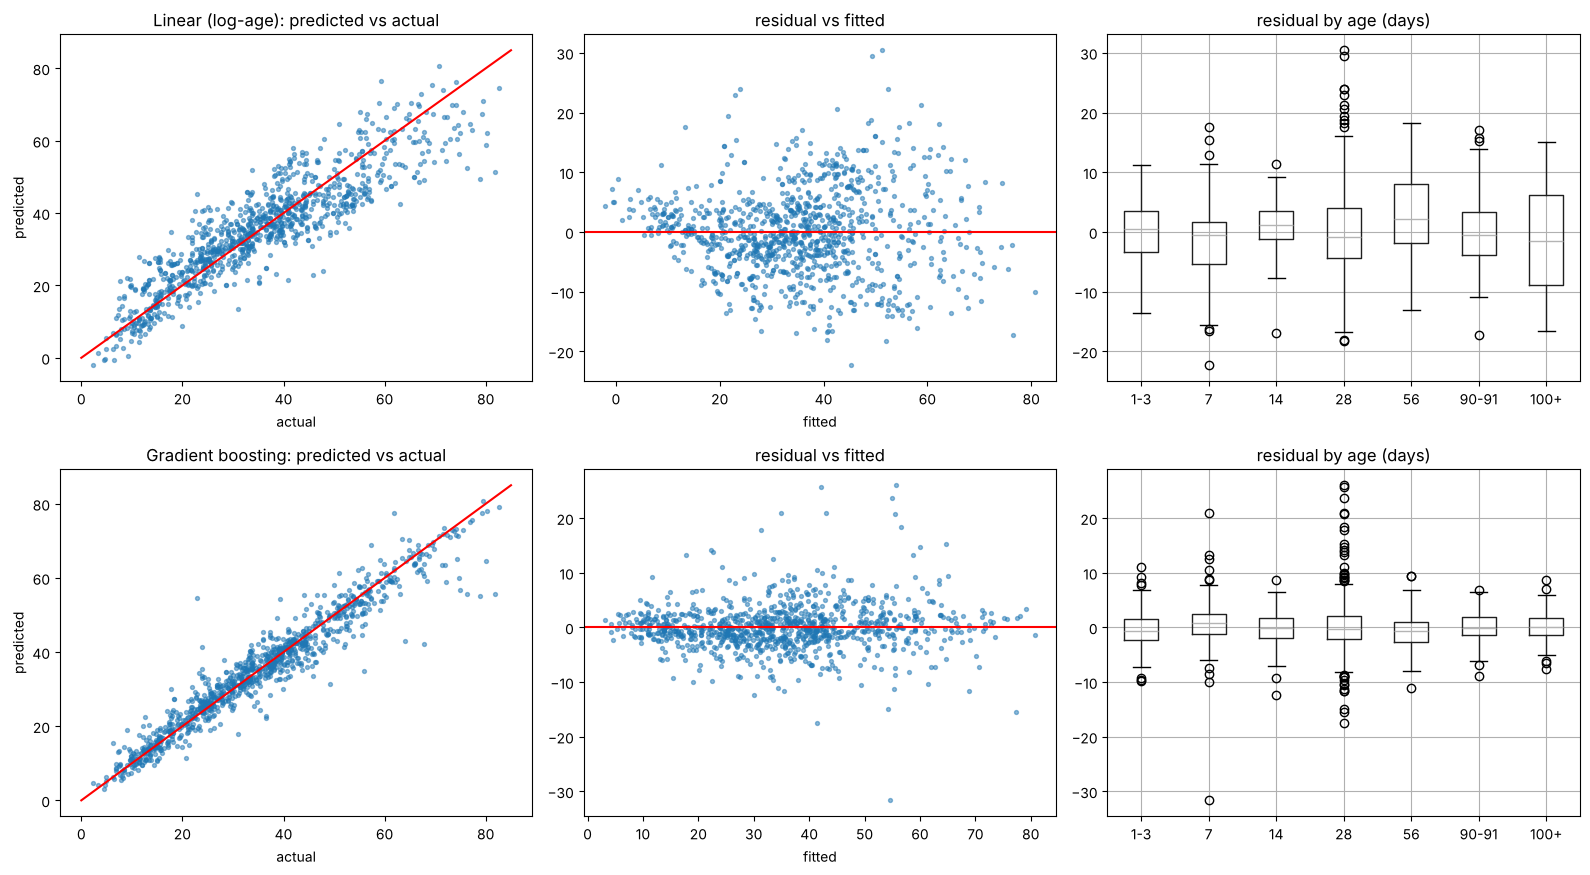

In [8]:
full = d.copy()
for n, k in [('Linear (log-age)','l'), ('Gradient boosting','g')]:
    full['p'+k] = cross_val_predict(models[n], X, y, cv=kf); full['r'+k] = y - full['p'+k]
print('OOF RMSE  linear: %.2f | boosting: %.2f' % (np.sqrt((full.rl**2).mean()), np.sqrt((full.rg**2).mean())))
print('Residual kurtosis  linear: %.2f | boosting: %.2f' % (full.rl.kurt(), full.rg.kurt()))

fig, ax = plt.subplots(2, 3, figsize=(16, 9))
full['agebin'] = pd.cut(full.age, [0,3,7,14,28,56,91,400], labels=['1-3','7','14','28','56','90-91','100+'])
for i, (n, p, r) in enumerate([('Linear (log-age)','pl','rl'), ('Gradient boosting','pg','rg')]):
    ax[i,0].scatter(y, full[p], s=8, alpha=.5); ax[i,0].plot([0,85],[0,85],'r'); ax[i,0].set_title(n+': predicted vs actual'); ax[i,0].set_xlabel('actual'); ax[i,0].set_ylabel('predicted')
    ax[i,1].scatter(full[p], full[r], s=8, alpha=.5); ax[i,1].axhline(0, color='r'); ax[i,1].set_title('residual vs fitted'); ax[i,1].set_xlabel('fitted')
    full.boxplot(column=r, by='agebin', ax=ax[i,2]); ax[i,2].set_title('residual by age (days)'); ax[i,2].set_xlabel('')
plt.suptitle(''); plt.tight_layout(); plt.savefig('figures/f3_resid.png'); plt.show()

In [9]:
full['strength_bin'] = pd.cut(full.strength, [0,20,30,40,50,60,90])
full['wc_quintile'] = pd.qcut(full.water/full.cement, 5)
for b in ['agebin', 'strength_bin', 'wc_quintile']:
    g = full.groupby(b).agg(n=('rl','size'),
        rmse_linear=('rl', lambda r: np.sqrt((r**2).mean())), rmse_boost=('rg', lambda r: np.sqrt((r**2).mean())),
        bias_linear=('rl','mean'), bias_boost=('rg','mean')).round(2)
    print('\nError by', b); display(g)


Error by agebin


,n,rmse_linear,rmse_boost,bias_linear,bias_boost
agebin,,,,,
1-3,131,5.49,3.47,-0.52,-0.40
7,122,6.70,5.03,-1.41,0.76
14,62,4.49,3.48,0.91,-0.13
28,419,7.53,5.18,0.30,0.19
56,86,7.50,3.45,2.69,-0.84
90-91,71,6.64,2.92,-0.05,0.10
100+,114,8.70,2.78,-1.45,0.28



Error by strength_bin


,n,rmse_linear,rmse_boost,bias_linear,bias_boost
strength_bin,,,,,
"(0, 20]",196,5.92,3.01,-2.25,-0.94
"(20, 30]",201,6.35,4.24,-3.37,-1.31
"(30, 40]",248,5.61,3.78,-1.00,-0.45
"(40, 50]",167,7.51,4.24,1.35,1.20
"(50, 60]",114,8.62,4.60,4.72,1.37
"(60, 90]",79,11.48,7.81,7.66,3.54



Error by wc_quintile


,n,rmse_linear,rmse_boost,bias_linear,bias_boost
wc_quintile,,,,,
"(0.266, 0.488]",203,8.29,6.18,-1.15,0.56
"(0.488, 0.615]",199,7.70,4.10,1.75,0.12
"(0.615, 0.752]",201,6.74,3.86,0.91,-0.02
"(0.752, 1.0]",204,6.26,3.58,-0.03,-0.01
"(1.0, 1.882]",198,6.41,3.53,-1.45,-0.27


**Where predictions are weakest**
- High-strength mixes (60-90 MPa): both models under-predict systematically (linear bias +7.7, boosting +3.5; RMSE 11.5 vs 7.8).
- Linear model: curved residual-vs-fitted pattern (wrong functional form); poor at 56 and 100+ days.
- Boosting: largest errors at 7 and 28 days and at low water/cement ratios (sparse, high-strength region); heavy-tailed residuals (kurtosis ~8).

## 3. Does the cement-strength association imply causation?

In [10]:
d2 = d.assign(log_age=np.log(d.age))
marg = LinearRegression().fit(d2[['cement']], d2.strength).coef_[0]
cols = ['cement','slag','flyash','water','sp','coarse','fine','log_age']
adj = LinearRegression().fit(d2[cols], d2.strength).coef_[0]
print(f'Cement slope, one-variable : {marg:.3f} MPa per kg/m3')
print(f'Cement slope, adjusted     : {adj:.3f} MPa per kg/m3  (same variable, different "effect")')
print('\nCorrelations among ingredients:'); display(d[['cement','water','slag','flyash','sp']].corr().round(2))
pi = permutation_importance(models['Gradient boosting'], Xte, yte, n_repeats=20, random_state=0)
print('\nPermutation importance (boosting):'); print(pd.Series(pi.importances_mean, index=X.columns).round(3).sort_values(ascending=False))

Cement slope, one-variable : 0.076 MPa per kg/m3
Cement slope, adjusted     : 0.132 MPa per kg/m3  (same variable, different "effect")

Correlations among ingredients:


,cement,water,slag,flyash,sp
cement,1.00,-0.06,-0.30,-0.39,0.06
water,-0.06,1.00,0.13,-0.28,-0.65
slag,-0.30,0.13,1.00,-0.31,0.02
flyash,-0.39,-0.28,-0.31,1.00,0.41
sp,0.06,-0.65,0.02,0.41,1.00



Permutation importance (boosting):
age       0.734
cement    0.567
water     0.168
slag      0.158
sp        0.059
fine      0.042
coarse    0.014
flyash    0.005
dtype: float64


**Answer: No.** A predictive association is not evidence of what will happen if we *change* the mixture.
1. **Observational data** - mixes were designed by researchers, not randomly assigned cement levels.
2. **Confounding / mixture constraints** - cement is correlated with slag (-0.30) and fly ash (-0.39); water and superplasticizer are linked (-0.65). Changing cement means changing something else. The cement slope itself changes (0.076 vs 0.132) depending on adjustment.
3. **Interactions** - the effect of cement depends on water, age and supplementary materials; model importance is not an intervention effect.
4. **Extrapolation** - unreliable outside observed combinations, where our error is already largest.
5. **Unmeasured factors** - cement type/fineness, curing conditions, specimen and test method.

A causal claim needs controlled experiments (vary cement, keep workability/water fixed, replicate specimens, randomise batches) or mechanistic knowledge (hydration chemistry, Abrams' law) combined with the model; use the model to screen candidates, then validate physically.